## Design the Traffic Management System

In [1]:
import sys
print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Python executable: C:\Users\aniket\anaconda3\python.exe


In [2]:
%pip install streamlit networkx matplotlib pandas numpy jupyter

Note: you may need to restart the kernel to use updated packages.


In [3]:
import streamlit as st
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

print("All libraries imported successfully!")
print("NetworkX version:", nx.__version__)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
NetworkX version: 3.6.1
Pandas version: 3.0.3
NumPy version: 2.4.6


In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a weighted, undirected road network
city = nx.Graph()

# Add intersections
intersections = [
    "A", "B", "C", "D", "E", "F"
]

city.add_nodes_from(intersections)

# Add roads with travel time in minutes
roads = [
    ("A", "B", 4),
    ("A", "C", 2),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 8),
    ("C", "E", 10),
    ("D", "E", 2),
    ("D", "F", 6),
    ("E", "F", 3)
]

for source, destination, travel_time in roads:
    city.add_edge(
        source,
        destination,
        weight=travel_time
    )

print("Intersections:", city.number_of_nodes())
print("Roads:", city.number_of_edges())
print("Is the city connected?", nx.is_connected(city))

Intersections: 6
Roads: 9
Is the city connected? True


In [5]:
pos = nx.spring_layout(city, seed=42)

plt.figure(figsize=(4, 5))

nx.draw(
    city,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=12,
    width=2
)

edge_labels = nx.get_edge_attributes(city, "weight")

nx.draw_networkx_edge_labels(
    city,
    pos,
    edge_labels=edge_labels,
    font_size=10
)

plt.title("Smart City Road Network")
plt.show()

C:\Users\aniket\AppData\Local\Temp\ipykernel_16200\1059709975.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [6]:
for intersection in city.nodes():
    neighbours = list(city.neighbors(intersection))

    print(f"{intersection}: {neighbours}")

A: ['B', 'C']
B: ['A', 'C', 'D']
C: ['A', 'B', 'D', 'E']
D: ['B', 'C', 'E', 'F']
E: ['C', 'D', 'F']
F: ['D', 'E']


In [7]:
adjacency_matrix = nx.to_pandas_adjacency(
    city,
    nodelist=sorted(city.nodes()),
    weight="weight"
)

display(adjacency_matrix)

,A,B,C,D,E,F
A,0.0,4.0,2.0,0.0,0.0,0.0
B,4.0,0.0,1.0,5.0,0.0,0.0
C,2.0,1.0,0.0,8.0,10.0,0.0
D,0.0,5.0,8.0,0.0,2.0,6.0
E,0.0,0.0,10.0,2.0,0.0,3.0
F,0.0,0.0,0.0,6.0,3.0,0.0


## Route Planning Module

In [8]:
import heapq

def dijkstra(graph, source, destination):
    # Initially, all distances are infinity
    distances = {node: float("inf") for node in graph.nodes()}
    distances[source] = 0

    # Store each node's predecessor
    previous = {node: None for node in graph.nodes()}

    # Priority queue: (distance, node)
    priority_queue = [(0, source)]

    # Record distance updates for the assignment
    updates = []

    while priority_queue:
        current_distance, current_node = heapq.heappop(priority_queue)

        # Ignore outdated queue entries
        if current_distance > distances[current_node]:
            continue

        # Stop once the destination is finalized
        if current_node == destination:
            break

        for neighbor in graph.neighbors(current_node):
            weight = graph[current_node][neighbor]["weight"]
            new_distance = current_distance + weight

            if new_distance < distances[neighbor]:
                distances[neighbor] = new_distance
                previous[neighbor] = current_node

                heapq.heappush(
                    priority_queue,
                    (new_distance, neighbor)
                )

                updates.append({
                    "From": current_node,
                    "To": neighbor,
                    "Updated Distance": new_distance
                })

    # Reconstruct the shortest path
    path = []
    current = destination

    if distances[destination] != float("inf"):
        while current is not None:
            path.append(current)
            current = previous[current]

        path.reverse()

    return path, distances[destination], updates

In [9]:
source = "A"
destination = "F"

path, total_cost, updates = dijkstra(
    city, source, destination
)

print("Source:", source)
print("Destination:", destination)
print("Shortest route:", " -> ".join(path))
print("Total travel time:", total_cost, "minutes")

print("\nIntermediate distance updates:")
display(pd.DataFrame(updates))

Source: A
Destination: F
Shortest route: A -> C -> B -> D -> E -> F
Total travel time: 13 minutes

Intermediate distance updates:


,From,To,Updated Distance
0,A,B,4
1,A,C,2
2,C,B,3
3,C,D,10
4,C,E,12
5,B,D,8
6,D,E,10
7,D,F,14
8,E,F,13


In [10]:
verified_path = nx.dijkstra_path(
    city, source, destination, weight="weight"
)

verified_cost = nx.dijkstra_path_length(
    city, source, destination, weight="weight"
)

print("Our route:", path)
print("NetworkX route:", verified_path)

print("Our cost:", total_cost)
print("NetworkX cost:", verified_cost)

assert path == verified_path
assert total_cost == verified_cost

print("\nTest passed! Both implementations agree.")

Our route: ['A', 'C', 'B', 'D', 'E', 'F']
NetworkX route: ['A', 'C', 'B', 'D', 'E', 'F']
Our cost: 13
NetworkX cost: 13

Test passed! Both implementations agree.


In [11]:
plt.figure(figsize=(4, 5))

nx.draw(
    city,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=12,
    width=2
)

nx.draw_networkx_edge_labels(
    city,
    pos,
    edge_labels=nx.get_edge_attributes(city, "weight")
)

route_edges = list(zip(path, path[1:]))

nx.draw_networkx_edges(
    city,
    pos,
    edgelist=route_edges,
    edge_color="red",
    width=4
)

plt.title(f"Shortest Route: {' -> '.join(path)} ({total_cost} min)")
plt.show()

C:\Users\aniket\AppData\Local\Temp\ipykernel_16200\690047780.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Traffic Analysis using Bellman–Ford

In [12]:
def bellman_ford(graph, source, destination):
    nodes = list(graph.nodes())

    distances = {node: float("inf") for node in nodes}
    previous = {node: None for node in nodes}
    distances[source] = 0

    # An undirected road is represented by two directed edges
    edges = []
    for u, v, data in graph.edges(data=True):
        weight = data["weight"]
        edges.append((u, v, weight))
        edges.append((v, u, weight))

    updates = []

    # Relax all edges at most V - 1 times
    for iteration in range(len(nodes) - 1):
        changed = False

        for u, v, weight in edges:
            if distances[u] != float("inf"):
                new_distance = distances[u] + weight

                if new_distance < distances[v]:
                    distances[v] = new_distance
                    previous[v] = u
                    changed = True

                    updates.append({
                        "Iteration": iteration + 1,
                        "From": u,
                        "To": v,
                        "New Distance": new_distance
                    })

        if not changed:
            break

    # Check for a reachable negative-weight cycle
    for u, v, weight in edges:
        if (distances[u] != float("inf")
                and distances[u] + weight < distances[v]):
            raise ValueError("Reachable negative-weight cycle detected.")

    # Reconstruct the route
    path = []
    current = destination

    if distances[destination] != float("inf"):
        while current is not None:
            path.append(current)
            current = previous[current]

        path.reverse()

    return path, distances[destination], updates

In [13]:
original_path, original_cost, original_updates = bellman_ford(
    city, "A", "F"
)

print("Original route:", " -> ".join(original_path))
print("Original travel time:", original_cost, "minutes")

Original route: A -> C -> B -> D -> E -> F
Original travel time: 13 minutes


In [14]:
congested_city = city.copy()

congested_city["D"]["E"]["weight"] = 10

print("Original D-E travel time:", city["D"]["E"]["weight"], "minutes")
print("Congested D-E travel time:",
      congested_city["D"]["E"]["weight"], "minutes")

Original D-E travel time: 2 minutes
Congested D-E travel time: 10 minutes


In [15]:
updated_path, updated_cost, updated_updates = bellman_ford(
    congested_city, "A", "F"
)

print("Updated route:", " -> ".join(updated_path))
print("Updated travel time:", updated_cost, "minutes")

print("\nIntermediate distance updates:")
display(pd.DataFrame(updated_updates))

Updated route: A -> C -> B -> D -> F
Updated travel time: 14 minutes

Intermediate distance updates:


,Iteration,From,To,New Distance
0,1,A,B,4
1,1,A,C,2
2,1,C,B,3
3,1,B,D,8
4,1,C,E,12
5,1,D,F,14


In [16]:
comparison = pd.DataFrame([
    {
        "Scenario": "Before congestion",
        "Route": " -> ".join(original_path),
        "Travel Time (min)": original_cost
    },
    {
        "Scenario": "After congestion",
        "Route": " -> ".join(updated_path),
        "Travel Time (min)": updated_cost
    }
])

display(comparison)

difference = updated_cost - original_cost

print("Change in travel time:", difference, "minutes")

if original_cost > 0:
    percentage = difference / original_cost * 100
    print(f"Percentage increase: {percentage:.2f}%")

,Scenario,Route,Travel Time (min)
0,Before congestion,A -> C -> B -> D -> E -> F,13
1,After congestion,A -> C -> B -> D -> F,14


Change in travel time: 1 minutes
Percentage increase: 7.69%


In [17]:
plt.figure(figsize=(4, 5))

nx.draw(
    congested_city,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=12,
    width=2
)

nx.draw_networkx_edge_labels(
    congested_city,
    pos,
    edge_labels=nx.get_edge_attributes(
        congested_city, "weight"
    )
)

nx.draw_networkx_edges(
    congested_city,
    pos,
    edgelist=list(zip(updated_path, updated_path[1:])),
    edge_color="red",
    width=4
)

plt.title(
    f"Route After Congestion: {updated_cost} minutes"
)
plt.show()

C:\Users\aniket\AppData\Local\Temp\ipykernel_16200\1472808673.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [18]:
verified_cost = nx.bellman_ford_path_length(
    congested_city, "A", "F", weight="weight"
)

assert updated_cost == verified_cost
assert updated_cost == 14
assert original_cost == 13

print("Traffic analysis tests passed!")

Traffic analysis tests passed!


## Network Connectivity Module using BFS and DFS

In [19]:
from collections import deque

def bfs(graph, start):
    visited = set()
    traversal_order = []
    queue = deque([start])

    visited.add(start)

    while queue:
        current = queue.popleft()
        traversal_order.append(current)

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return traversal_order

In [20]:
def dfs(graph, start):
    visited = set()
    traversal_order = []

    def explore(current):
        visited.add(current)
        traversal_order.append(current)

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                explore(neighbor)

    explore(start)

    return traversal_order

In [21]:
start = "A"

bfs_order = bfs(city, start)
dfs_order = dfs(city, start)

print("Starting intersection:", start)
print("BFS traversal:", " -> ".join(bfs_order))
print("DFS traversal:", " -> ".join(dfs_order))

print("\nReachable intersections:", len(bfs_order))
print("Total intersections:", city.number_of_nodes())

Starting intersection: A
BFS traversal: A -> B -> C -> D -> E -> F
DFS traversal: A -> B -> C -> D -> E -> F

Reachable intersections: 6
Total intersections: 6


In [22]:
connectivity_results = pd.DataFrame([
    {
        "Algorithm": "BFS",
        "Starting Intersection": start,
        "Traversal Order": " -> ".join(bfs_order),
        "Reachable Count": len(bfs_order)
    },
    {
        "Algorithm": "DFS",
        "Starting Intersection": start,
        "Traversal Order": " -> ".join(dfs_order),
        "Reachable Count": len(dfs_order)
    }
])

display(connectivity_results)

,Algorithm,Starting Intersection,Traversal Order,Reachable Count
0,BFS,A,A -> B -> C -> D -> E -> F,6
1,DFS,A,A -> B -> C -> D -> E -> F,6


In [23]:
plt.figure(figsize=(5, 5))

node_colors = [
    "orange" if node == start else
    "lightgreen" if node in bfs_order else
    "lightgray"
    for node in city.nodes()
]

nx.draw(
    city,
    pos,
    with_labels=True,
    node_color=node_colors,
    node_size=1800,
    font_size=12,
    width=2
)

nx.draw_networkx_edge_labels(
    city,
    pos,
    edge_labels=nx.get_edge_attributes(city, "weight")
)

plt.title("Network Connectivity — BFS Reachability")
plt.show()

C:\Users\aniket\AppData\Local\Temp\ipykernel_16200\3720381038.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [24]:
%matplotlib inline

In [25]:
expected_bfs = list(nx.bfs_tree(city, "A"))
expected_dfs = list(nx.dfs_preorder_nodes(city, "A"))

assert bfs_order == expected_bfs
assert dfs_order == expected_dfs
assert set(bfs_order) == set(dfs_order)

print("BFS verification passed!")
print("DFS verification passed!")
print("Reachability verification passed!")

BFS verification passed!
DFS verification passed!
Reachability verification passed!


In [26]:
test_city = city.copy()
test_city.add_node("G")  # An isolated intersection

print("BFS from A:", bfs(test_city, "A"))
print("Reachable from A:", len(bfs(test_city, "A")))
print("Total intersections:", test_city.number_of_nodes())

assert len(bfs(test_city, "A")) == 6
assert len(dfs(test_city, "A")) == 6

print("Disconnected network test passed!")

BFS from A: ['A', 'B', 'C', 'D', 'E', 'F']
Reachable from A: 6
Total intersections: 7
Disconnected network test passed!


## Infrastructure Planning

In [27]:
import heapq

def prim_mst(graph, start=None):
    if len(graph) == 0:
        return [], 0

    if not nx.is_connected(graph):
        raise ValueError("MST requires a connected graph.")

    if start is None:
        start = next(iter(graph.nodes()))

    if start not in graph:
        raise ValueError("Starting intersection does not exist.")

    visited = {start}
    min_heap = []
    mst_edges = []
    total_cost = 0

    for neighbor, data in graph[start].items():
        heapq.heappush(
            min_heap,
            (data["weight"], start, neighbor)
        )

    while min_heap and len(visited) < len(graph):
        weight, u, v = heapq.heappop(min_heap)

        if v in visited:
            continue

        visited.add(v)
        mst_edges.append((u, v, weight))
        total_cost += weight

        for neighbor, data in graph[v].items():
            if neighbor not in visited:
                heapq.heappush(
                    min_heap,
                    (data["weight"], v, neighbor)
                )

    return mst_edges, total_cost

In [28]:
prim_edges, prim_cost = prim_mst(city, start="A")

print("Prim's MST roads:")
for u, v, weight in prim_edges:
    print(f"{u} -- {v}: {weight}")

print("\nTotal infrastructure cost:", prim_cost)
print("Number of selected roads:", len(prim_edges))

Prim's MST roads:
A -- C: 2
C -- B: 1
B -- D: 5
D -- E: 2
E -- F: 3

Total infrastructure cost: 13
Number of selected roads: 5


In [29]:
def kruskal_mst(graph):
    if len(graph) == 0:
        return [], 0

    if not nx.is_connected(graph):
        raise ValueError("MST requires a connected graph.")

    parent = {node: node for node in graph.nodes()}
    rank = {node: 0 for node in graph.nodes()}

    def find(node):
        if parent[node] != node:
            parent[node] = find(parent[node])
        return parent[node]

    def union(u, v):
        root_u = find(u)
        root_v = find(v)

        if root_u == root_v:
            return False

        if rank[root_u] < rank[root_v]:
            parent[root_u] = root_v
        elif rank[root_u] > rank[root_v]:
            parent[root_v] = root_u
        else:
            parent[root_v] = root_u
            rank[root_u] += 1

        return True

    edges = sorted(
        (data["weight"], u, v)
        for u, v, data in graph.edges(data=True)
    )

    mst_edges = []
    total_cost = 0

    for weight, u, v in edges:
        if union(u, v):
            mst_edges.append((u, v, weight))
            total_cost += weight

            if len(mst_edges) == len(graph) - 1:
                break

    return mst_edges, total_cost

In [30]:
kruskal_edges, kruskal_cost = kruskal_mst(city)

print("Kruskal's MST roads:")
for u, v, weight in kruskal_edges:
    print(f"{u} -- {v}: {weight}")

print("\nTotal infrastructure cost:", kruskal_cost)
print("Number of selected roads:", len(kruskal_edges))

Kruskal's MST roads:
B -- C: 1
A -- C: 2
D -- E: 2
E -- F: 3
B -- D: 5

Total infrastructure cost: 13
Number of selected roads: 5


In [31]:
mst_comparison = pd.DataFrame([
    {
        "Algorithm": "Prim",
        "Selected Roads": len(prim_edges),
        "Total Cost": prim_cost
    },
    {
        "Algorithm": "Kruskal",
        "Selected Roads": len(kruskal_edges),
        "Total Cost": kruskal_cost
    }
])

display(mst_comparison)

assert len(prim_edges) == len(city.nodes()) - 1
assert len(kruskal_edges) == len(city.nodes()) - 1
assert prim_cost == kruskal_cost == 13

print("MST verification passed!")

,Algorithm,Selected Roads,Total Cost
0,Prim,5,13
1,Kruskal,5,13


MST verification passed!


In [32]:
reference_mst = nx.minimum_spanning_tree(
    city,
    algorithm="kruskal",
    weight="weight"
)

reference_cost = sum(
    data["weight"]
    for _, _, data in reference_mst.edges(data=True)
)

print("Our Prim cost:", prim_cost)
print("Our Kruskal cost:", kruskal_cost)
print("NetworkX reference cost:", reference_cost)

assert prim_cost == reference_cost
assert kruskal_cost == reference_cost

print("All MST tests passed!")

Our Prim cost: 13
Our Kruskal cost: 13
NetworkX reference cost: 13
All MST tests passed!


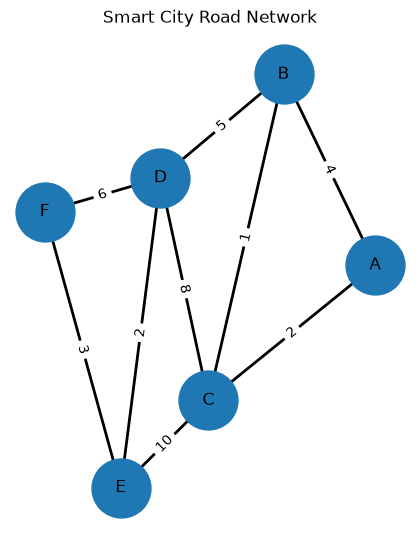

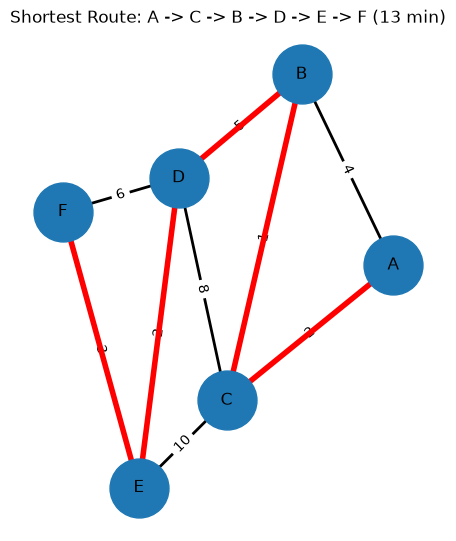

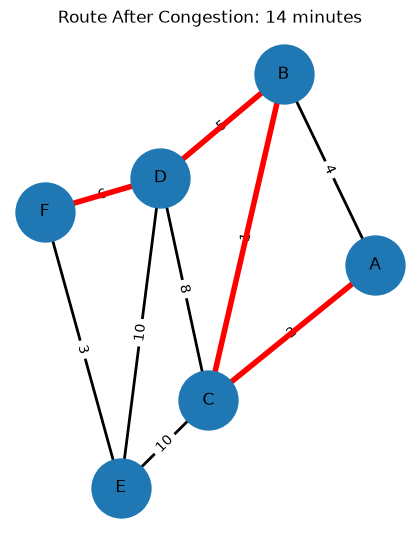

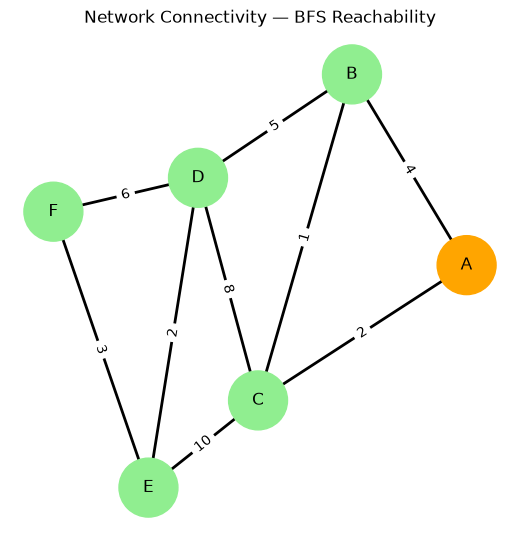

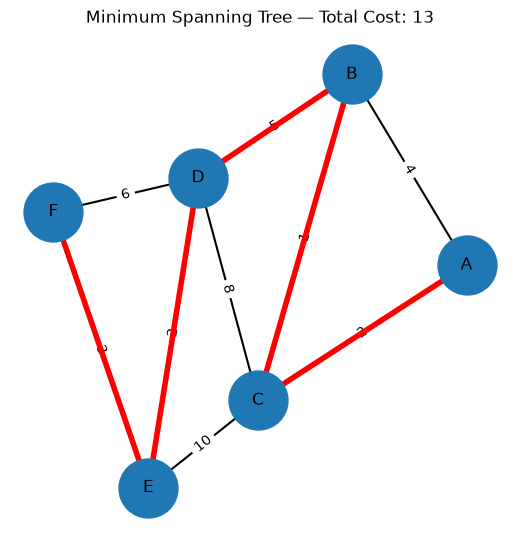

In [33]:
plt.figure(figsize=(5, 5))

nx.draw(
    city,
    pos,
    with_labels=True,
    node_size=1800,
    font_size=12,
    width=1.5
)

nx.draw_networkx_edge_labels(
    city,
    pos,
    edge_labels=nx.get_edge_attributes(city, "weight")
)

mst_graph = nx.Graph()
mst_graph.add_nodes_from(city.nodes())
mst_graph.add_weighted_edges_from(prim_edges)

nx.draw_networkx_edges(
    mst_graph,
    pos,
    edgelist=list(mst_graph.edges()),
    edge_color="red",
    width=4
)

plt.title(f"Minimum Spanning Tree — Total Cost: {prim_cost}")
plt.show()

## Comparative Performance Analysis

In [34]:
import random
import networkx as nx

def generate_city(num_intersections, seed=42):
    rng = random.Random(seed)

    # Create intersection names
    nodes = [f"I{i}" for i in range(num_intersections)]

    graph = nx.Graph()
    graph.add_nodes_from(nodes)

    # Create a connected random spanning tree
    shuffled_nodes = nodes.copy()
    rng.shuffle(shuffled_nodes)

    for i in range(1, num_intersections):
        parent = rng.choice(shuffled_nodes[:i])
        current = shuffled_nodes[i]
        graph.add_edge(parent, current)

    # Add extra roads
    target_edges = min(
        num_intersections * 3,
        num_intersections * (num_intersections - 1) // 2
    )

    while graph.number_of_edges() < target_edges:
        u, v = rng.sample(nodes, 2)

        if not graph.has_edge(u, v):
            graph.add_edge(u, v)

    # Assign positive road weights
    for u, v in graph.edges():
        graph[u][v]["weight"] = rng.randint(1, 20)

    return graph

In [35]:
network_sizes = [10, 25, 50, 100]

test_cities = {
    size: generate_city(size, seed=42 + size)
    for size in network_sizes
}

for size, graph in test_cities.items():
    print(
        f"Intersections: {graph.number_of_nodes()}, "
        f"Roads: {graph.number_of_edges()}, "
        f"Connected: {nx.is_connected(graph)}"
    )

Intersections: 10, Roads: 30, Connected: True
Intersections: 25, Roads: 75, Connected: True
Intersections: 50, Roads: 150, Connected: True
Intersections: 100, Roads: 300, Connected: True


In [36]:
import time
import statistics
import pandas as pd
import numpy as np

def measure_time(function, repeats=7):
    timings = []

    for _ in range(repeats):
        start_time = time.perf_counter()

        function()

        end_time = time.perf_counter()
        timings.append(end_time - start_time)

    return statistics.median(timings)

In [37]:
test_time = measure_time(
    lambda: sum(range(10000))
)

print(f"Test execution time: {test_time * 1000:.4f} ms")

Test execution time: 0.4159 ms


In [38]:
traversal_results = []

for size, graph in test_cities.items():
    start = "I0"

    bfs_time = measure_time(
        lambda: bfs(graph, start)
    )

    dfs_time = measure_time(
        lambda: dfs(graph, start)
    )

    traversal_results.append({
        "Intersections": size,
        "Roads": graph.number_of_edges(),
        "BFS Time (ms)": bfs_time * 1000,
        "DFS Time (ms)": dfs_time * 1000,
        "BFS Visited": len(bfs(graph, start)),
        "DFS Visited": len(dfs(graph, start))
    })

bfs_dfs_df = pd.DataFrame(traversal_results)

display(bfs_dfs_df.round(4))

,Intersections,Roads,BFS Time (ms),DFS Time (ms),BFS Visited,DFS Visited
0,10,30,0.0277,0.0256,10,10
1,25,75,0.0632,0.0667,25,25
2,50,150,0.1236,0.1261,50,50
3,100,300,0.2571,0.2843,100,100


In [39]:
route_results = []

for size, graph in test_cities.items():
    source = "I0"
    destination = f"I{size - 1}"

    # Measure execution times
    dijkstra_time = measure_time(
        lambda: dijkstra(graph, source, destination)
    )

    bellman_time = measure_time(
        lambda: bellman_ford(graph, source, destination)
    )

    # Calculate route costs
    dijkstra_path, dijkstra_cost, _ = dijkstra(
        graph, source, destination
    )

    bellman_path, bellman_cost, _ = bellman_ford(
        graph, source, destination
    )

    # Verify both algorithms find the same minimum cost
    assert dijkstra_cost == bellman_cost, (
        f"Cost mismatch for network size {size}"
    )

    route_results.append({
        "Intersections": size,
        "Roads": graph.number_of_edges(),
        "Dijkstra Time (ms)": dijkstra_time * 1000,
        "Bellman-Ford Time (ms)": bellman_time * 1000,
        "Dijkstra Cost": dijkstra_cost,
        "Bellman-Ford Cost": bellman_cost,
        "Route Roads": len(dijkstra_path) - 1
    })

route_df = pd.DataFrame(route_results)

display(route_df.round(4))
print("All shortest-path cost comparisons passed!")

,Intersections,Roads,Dijkstra Time (ms),Bellman-Ford Time (ms),Dijkstra Cost,Bellman-Ford Cost,Route Roads
0,10,30,0.1569,0.2654,9,9,1
1,25,75,0.2391,0.8583,9,9,3
2,50,150,0.3956,2.0048,11,11,4
3,100,300,1.9504,4.9015,24,24,4


All shortest-path cost comparisons passed!


In [40]:
mst_results = []

for size, graph in test_cities.items():

    # Measure execution time
    prim_time = measure_time(
        lambda: prim_mst(graph)
    )

    kruskal_time = measure_time(
        lambda: kruskal_mst(graph)
    )

    # Calculate MSTs
    prim_edges, prim_cost = prim_mst(graph)
    kruskal_edges, kruskal_cost = kruskal_mst(graph)

    # Verify the results
    assert prim_cost == kruskal_cost
    assert len(prim_edges) == size - 1
    assert len(kruskal_edges) == size - 1

    mst_results.append({
        "Intersections": size,
        "Roads": graph.number_of_edges(),
        "Prim Time (ms)": prim_time * 1000,
        "Kruskal Time (ms)": kruskal_time * 1000,
        "Prim MST Cost": prim_cost,
        "Kruskal MST Cost": kruskal_cost
    })

mst_df = pd.DataFrame(mst_results)

display(mst_df.round(4))
print("All MST comparisons passed!")

,Intersections,Roads,Prim Time (ms),Kruskal Time (ms),Prim MST Cost,Kruskal MST Cost
0,10,30,0.2048,0.2068,32,32
1,25,75,0.5903,0.4869,107,107
2,50,150,0.9873,0.8469,260,260
3,100,300,2.3873,1.7942,440,440


All MST comparisons passed!


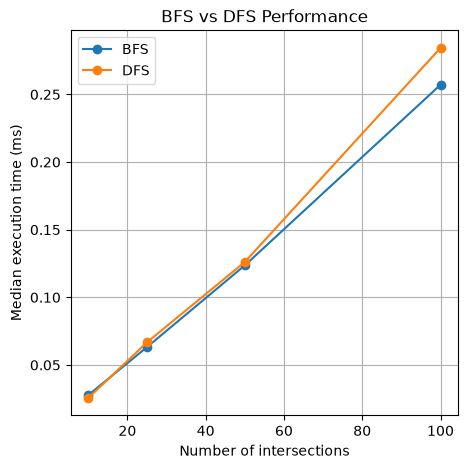

In [41]:
plt.figure(figsize=(5, 5))

plt.plot(
    bfs_dfs_df["Intersections"],
    bfs_dfs_df["BFS Time (ms)"],
    marker="o",
    label="BFS"
)

plt.plot(
    bfs_dfs_df["Intersections"],
    bfs_dfs_df["DFS Time (ms)"],
    marker="o",
    label="DFS"
)

plt.xlabel("Number of intersections")
plt.ylabel("Median execution time (ms)")
plt.title("BFS vs DFS Performance")
plt.legend()
plt.grid(True)
plt.show()

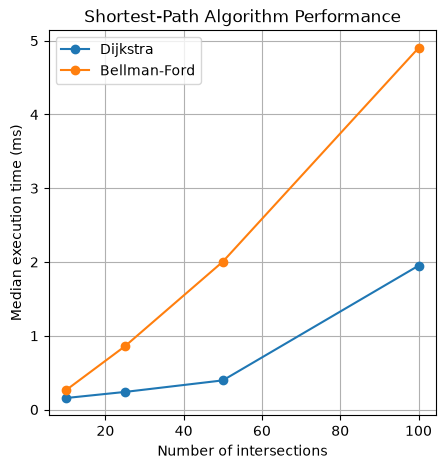

In [42]:
plt.figure(figsize=(5, 5))

plt.plot(
    route_df["Intersections"],
    route_df["Dijkstra Time (ms)"],
    marker="o",
    label="Dijkstra"
)

plt.plot(
    route_df["Intersections"],
    route_df["Bellman-Ford Time (ms)"],
    marker="o",
    label="Bellman-Ford"
)

plt.xlabel("Number of intersections")
plt.ylabel("Median execution time (ms)")
plt.title("Shortest-Path Algorithm Performance")
plt.legend()
plt.grid(True)
plt.show()

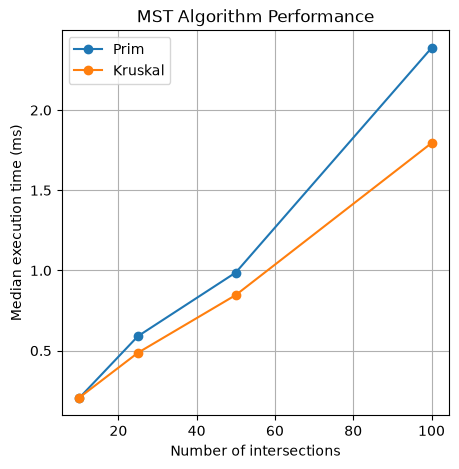

In [43]:
plt.figure(figsize=(5, 5))

plt.plot(
    mst_df["Intersections"],
    mst_df["Prim Time (ms)"],
    marker="o",
    label="Prim"
)

plt.plot(
    mst_df["Intersections"],
    mst_df["Kruskal Time (ms)"],
    marker="o",
    label="Kruskal"
)

plt.xlabel("Number of intersections")
plt.ylabel("Median execution time (ms)")
plt.title("MST Algorithm Performance")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
bfs_dfs_df.to_csv(
    "bfs_dfs_comparison.csv", index=False
)

route_df.to_csv(
    "dijkstra_bellman_ford_comparison.csv", index=False
)

mst_df.to_csv(
    "prim_kruskal_comparison.csv", index=False
)

print("All three comparison tables saved!")

All three comparison tables saved!


In [45]:
import os
print(os.getcwd())

C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment


In [46]:
from pathlib import Path

# Create the main project folder
current_folder = Path.cwd()

if current_folder.name == "smart-city-traffic-system":
    project_folder = current_folder
else:
    project_folder = current_folder / "smart-city-traffic-system"

project_folder.mkdir(parents=True, exist_ok=True)

# Create required subfolders
folders = [
    "screenshots",
    "report"
]

for folder in folders:
    (project_folder / folder).mkdir(exist_ok=True)

# Create required files without overwriting existing work
files = [
    "app.py",
    "route_planner.py",
    "traffic_analysis.py",
    "connectivity_module.py",
    "mst_planner.py",
    "project_notebook.ipynb",
    "requirements.txt",
    "README.md",
    ".gitignore"
]

for filename in files:
    filepath = project_folder / filename

    if not filepath.exists():
        filepath.touch()

print("Project structure created!")
print("Project location:", project_folder)

print("\nFiles and folders:")
for item in sorted(project_folder.iterdir()):
    print(item.name + ("/" if item.is_dir() else ""))

Project structure created!
Project location: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system

Files and folders:
.gitignore
app.py
connectivity_module.py
mst_planner.py
project_notebook.ipynb
README.md
report/
requirements.txt
route_planner.py
screenshots/
traffic_analysis.py


In [47]:
import os

os.chdir(project_folder)
print("Current working directory:", os.getcwd())

Current working directory: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system


In [48]:
print("Project folder:", project_folder)
print("Folder exists:", project_folder.exists())
print("Files and folders:")

for item in sorted(project_folder.iterdir()):
    print(item.name)

Project folder: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system
Folder exists: True
Files and folders:
.gitignore
app.py
connectivity_module.py
mst_planner.py
project_notebook.ipynb
README.md
report
requirements.txt
route_planner.py
screenshots
traffic_analysis.py


In [49]:
import os

os.chdir(project_folder)

print("Current directory:", os.getcwd())

Current directory: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system


In [50]:
from pathlib import Path

print("Project folder:", Path.cwd())
print("\nFiles currently in this folder:")

for item in sorted(Path.cwd().iterdir()):
    print(item.name)

Project folder: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system

Files currently in this folder:
.gitignore
app.py
connectivity_module.py
mst_planner.py
project_notebook.ipynb
README.md
report
requirements.txt
route_planner.py
screenshots
traffic_analysis.py


In [51]:
from pathlib import Path

required_files = [
    "app.py",
    "route_planner.py",
    "traffic_analysis.py",
    "connectivity_module.py",
    "mst_planner.py",
    "requirements.txt",
    "README.md",
    ".gitignore"
]

for filename in required_files:
    path = Path(filename)

    if not path.exists():
        path.touch()

print("Required Python files created or already present!")

Required Python files created or already present!


In [52]:
from pathlib import Path

project_folder = Path.cwd()

print("Current folder:", project_folder)
print("\nProject files:")

for item in sorted(project_folder.iterdir()):
    print(item.name)

Current folder: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system

Project files:
.gitignore
app.py
connectivity_module.py
mst_planner.py
project_notebook.ipynb
README.md
report
requirements.txt
route_planner.py
screenshots
traffic_analysis.py


In [53]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Project folder exists:", Path("route_planner.py").exists())

Current directory: C:\Users\aniket\Desktop\krmu class work\DAA\Capstone Assignment\smart-city-traffic-system
Project folder exists: True


In [54]:
%%writefile route_planner.py
import heapq
import math


def dijkstra(graph, source, destination):
    """Find the shortest route using Dijkstra's algorithm."""

    if source not in graph or destination not in graph:
        raise ValueError("Source or destination does not exist.")

    for _, _, data in graph.edges(data=True):
        weight = data.get("weight", 1)

        if not math.isfinite(weight) or weight < 0:
            raise ValueError(
                "Dijkstra requires finite, non-negative road weights."
            )

    distances = {node: float("inf") for node in graph.nodes()}
    previous = {node: None for node in graph.nodes()}

    distances[source] = 0
    priority_queue = [(0, source)]
    updates = []

    while priority_queue:
        current_distance, current_node = heapq.heappop(priority_queue)

        if current_distance > distances[current_node]:
            continue

        if current_node == destination:
            break

        for neighbor in graph.neighbors(current_node):
            weight = graph[current_node][neighbor].get("weight", 1)
            new_distance = current_distance + weight

            if new_distance < distances[neighbor]:
                distances[neighbor] = new_distance
                previous[neighbor] = current_node

                heapq.heappush(
                    priority_queue,
                    (new_distance, neighbor)
                )

                updates.append({
                    "From": current_node,
                    "To": neighbor,
                    "Updated Distance": new_distance
                })

    path = []

    if math.isfinite(distances[destination]):
        current = destination

        while current is not None:
            path.append(current)
            current = previous[current]

        path.reverse()

    return path, distances[destination], updates

Overwriting route_planner.py


In [55]:
import importlib
import route_planner
import networkx as nx

importlib.reload(route_planner)

test_graph = nx.Graph()
test_graph.add_weighted_edges_from([
    ("A", "B", 4),
    ("A", "C", 2),
    ("C", "B", 1),
    ("B", "D", 5),
    ("C", "D", 8)
])

path, cost, updates = route_planner.dijkstra(
    test_graph, "A", "D"
)

print("Shortest route:", " -> ".join(path))
print("Total cost:", cost)
print("Distance updates:", len(updates))

assert cost == nx.dijkstra_path_length(
    test_graph, "A", "D", weight="weight"
)

print("Dijkstra module test passed!")

Shortest route: A -> C -> B -> D
Total cost: 8
Distance updates: 5
Dijkstra module test passed!


In [56]:
%%writefile traffic_analysis.py
import math


def bellman_ford(graph, source, destination):
    """Find the shortest route using Bellman-Ford."""

    if source not in graph or destination not in graph:
        raise ValueError("Source or destination does not exist.")

    nodes = list(graph.nodes())
    distances = {node: float("inf") for node in nodes}
    previous = {node: None for node in nodes}

    distances[source] = 0
    updates = []

    # Represent undirected roads in both directions
    edges = []

    for u, v, data in graph.edges(data=True):
        weight = data.get("weight", 1)

        if not math.isfinite(weight):
            raise ValueError("Road weights must be finite.")

        edges.append((u, v, weight))
        edges.append((v, u, weight))

    # Relax edges at most V - 1 times
    for iteration in range(len(nodes) - 1):
        changed = False

        for u, v, weight in edges:
            if distances[u] != float("inf"):
                new_distance = distances[u] + weight

                if new_distance < distances[v]:
                    distances[v] = new_distance
                    previous[v] = u
                    changed = True

                    updates.append({
                        "Iteration": iteration + 1,
                        "From": u,
                        "To": v,
                        "Updated Distance": new_distance
                    })

        if not changed:
            break

    # Detect reachable negative-weight cycles
    for u, v, weight in edges:
        if (distances[u] != float("inf")
                and distances[u] + weight < distances[v]):
            raise ValueError("Reachable negative-weight cycle detected.")

    # Reconstruct the route
    path = []

    if math.isfinite(distances[destination]):
        current = destination

        while current is not None:
            path.append(current)
            current = previous[current]

        path.reverse()

    return path, distances[destination], updates


def simulate_congestion(graph, u, v, new_weight):
    """Return a copy of the graph with a modified road weight."""

    if not graph.has_edge(u, v):
        raise ValueError("The specified road does not exist.")

    if not math.isfinite(new_weight) or new_weight < 0:
        raise ValueError("Travel time must be finite and non-negative.")

    updated_graph = graph.copy()
    updated_graph[u][v]["weight"] = new_weight

    return updated_graph

Overwriting traffic_analysis.py


In [57]:
print("Nodes:", list(test_graph.nodes()))
print("Edges:", list(test_graph.edges()))
print("Is connected:", nx.is_connected(test_graph))

Nodes: ['A', 'B', 'C', 'D']
Edges: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
Is connected: True


In [58]:
import networkx as nx

# Create the original six-intersection city graph
test_graph = nx.Graph()

test_graph.add_weighted_edges_from([
    ("A", "B", 4),
    ("A", "C", 2),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 8),
    ("C", "E", 10),
    ("D", "E", 2),
    ("D", "F", 6),
    ("E", "F", 3)
])

# Verify original route
expected_original_cost = nx.bellman_ford_path_length(
    test_graph, "A", "F", weight="weight"
)

# Create congested graph
congested_graph = test_graph.copy()
congested_graph["D"]["E"]["weight"] = 10

# Verify updated route
expected_updated_cost = nx.bellman_ford_path_length(
    congested_graph, "A", "F", weight="weight"
)

print("Original cost:", original_cost)
print("NetworkX original cost:", expected_original_cost)

print("Updated cost:", updated_cost)
print("NetworkX updated cost:", expected_updated_cost)

assert original_cost == expected_original_cost == 13
assert updated_cost == expected_updated_cost == 14
assert original_path != updated_path

print("\nTraffic analysis module test passed!")

Original cost: 13
NetworkX original cost: 13
Updated cost: 14
NetworkX updated cost: 14

Traffic analysis module test passed!


In [59]:
%%writefile connectivity_module.py
from collections import deque


def bfs(graph, start):
    """Return BFS traversal order from the starting intersection."""

    if start not in graph:
        raise ValueError("Starting intersection does not exist.")

    visited = {start}
    traversal_order = []
    queue = deque([start])

    while queue:
        current = queue.popleft()
        traversal_order.append(current)

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return traversal_order


def dfs(graph, start):
    """Return DFS traversal order from the starting intersection."""

    if start not in graph:
        raise ValueError("Starting intersection does not exist.")

    visited = set()
    traversal_order = []

    def explore(current):
        visited.add(current)
        traversal_order.append(current)

        for neighbor in graph.neighbors(current):
            if neighbor not in visited:
                explore(neighbor)

    explore(start)

    return traversal_order

Overwriting connectivity_module.py


In [60]:
import importlib
import connectivity_module
import networkx as nx

importlib.reload(connectivity_module)

bfs_order = connectivity_module.bfs(city, "A")
dfs_order = connectivity_module.dfs(city, "A")

print("BFS traversal:", " -> ".join(bfs_order))
print("DFS traversal:", " -> ".join(dfs_order))

print("\nBFS visited:", len(bfs_order))
print("DFS visited:", len(dfs_order))

assert bfs_order == list(nx.bfs_tree(city, "A"))
assert dfs_order == list(nx.dfs_preorder_nodes(city, "A"))

assert len(bfs_order) == city.number_of_nodes()
assert len(dfs_order) == city.number_of_nodes()

print("\nConnectivity module tests passed!")

BFS traversal: A -> B -> C -> D -> E -> F
DFS traversal: A -> B -> C -> D -> E -> F

BFS visited: 6
DFS visited: 6

Connectivity module tests passed!


In [61]:
try:
    connectivity_module.bfs(city, "Z")
except ValueError as error:
    print("Error handled correctly:", error)

Error handled correctly: Starting intersection does not exist.


In [62]:
%%writefile mst_planner.py
import heapq


def prim_mst(graph, start=None):
    """Return MST edges and total cost using Prim's algorithm."""

    if len(graph) == 0:
        return [], 0

    if not graph.is_directed() and not __import__(
        "networkx"
    ).is_connected(graph):
        raise ValueError("MST requires a connected graph.")

    if graph.is_directed():
        raise ValueError("MST requires an undirected graph.")

    if start is None:
        start = next(iter(graph.nodes()))

    if start not in graph:
        raise ValueError("Starting intersection does not exist.")

    visited = {start}
    min_heap = []
    mst_edges = []
    total_cost = 0

    for neighbor, data in graph[start].items():
        heapq.heappush(
            min_heap,
            (data.get("weight", 1), start, neighbor)
        )

    while min_heap and len(visited) < len(graph):
        weight, u, v = heapq.heappop(min_heap)

        if v in visited:
            continue

        visited.add(v)
        mst_edges.append((u, v, weight))
        total_cost += weight

        for neighbor, data in graph[v].items():
            if neighbor not in visited:
                heapq.heappush(
                    min_heap,
                    (data.get("weight", 1), v, neighbor)
                )

    return mst_edges, total_cost


def kruskal_mst(graph):
    """Return MST edges and total cost using Kruskal's algorithm."""

    if len(graph) == 0:
        return [], 0

    if graph.is_directed():
        raise ValueError("MST requires an undirected graph.")

    import networkx as nx

    if not nx.is_connected(graph):
        raise ValueError("MST requires a connected graph.")

    parent = {node: node for node in graph.nodes()}
    rank = {node: 0 for node in graph.nodes()}

    def find(node):
        if parent[node] != node:
            parent[node] = find(parent[node])
        return parent[node]

    def union(u, v):
        root_u = find(u)
        root_v = find(v)

        if root_u == root_v:
            return False

        if rank[root_u] < rank[root_v]:
            parent[root_u] = root_v
        elif rank[root_u] > rank[root_v]:
            parent[root_v] = root_u
        else:
            parent[root_v] = root_u
            rank[root_u] += 1

        return True

    edges = sorted(
        (
            data.get("weight", 1),
            u,
            v
        )
        for u, v, data in graph.edges(data=True)
    )

    mst_edges = []
    total_cost = 0

    for weight, u, v in edges:
        if union(u, v):
            mst_edges.append((u, v, weight))
            total_cost += weight

            if len(mst_edges) == len(graph) - 1:
                break

    return mst_edges, total_cost

Overwriting mst_planner.py


In [63]:
import importlib
import mst_planner
import networkx as nx

importlib.reload(mst_planner)

prim_edges, prim_cost = mst_planner.prim_mst(city, start="A")
kruskal_edges, kruskal_cost = mst_planner.kruskal_mst(city)

print("Prim's MST cost:", prim_cost)
print("Prim's selected roads:", len(prim_edges))

print("\nKruskal's MST cost:", kruskal_cost)
print("Kruskal's selected roads:", len(kruskal_edges))

reference_mst = nx.minimum_spanning_tree(
    city,
    algorithm="kruskal",
    weight="weight"
)

reference_cost = sum(
    data["weight"]
    for _, _, data in reference_mst.edges(data=True)
)

assert prim_cost == reference_cost
assert kruskal_cost == reference_cost
assert len(prim_edges) == len(city) - 1
assert len(kruskal_edges) == len(city) - 1

print("\nMST module tests passed!")

Prim's MST cost: 13
Prim's selected roads: 5

Kruskal's MST cost: 13
Kruskal's selected roads: 5

MST module tests passed!


## Creating App.py

In [64]:

%%writefile app.py

import streamlit as st
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from route_planner import dijkstra
from traffic_analysis import bellman_ford, simulate_congestion
from connectivity_module import bfs, dfs
from mst_planner import prim_mst, kruskal_mst


st.set_page_config(
    page_title="Smart City Traffic Management",
    page_icon="🚦",
    layout="wide"
)

st.title("🚦 Smart City Traffic Management System")
st.write(
    "Plan routes, analyze traffic congestion, explore connectivity, "
    "and optimize road infrastructure."
)


# Create the sample city network
def create_city():
    graph = nx.Graph()

    roads = [
        ("A", "B", 4),
        ("A", "C", 2),
        ("B", "C", 1),
        ("B", "D", 5),
        ("C", "D", 8),
        ("C", "E", 10),
        ("D", "E", 2),
        ("D", "F", 6),
        ("E", "F", 3)
    ]

    for u, v, weight in roads:
        graph.add_edge(u, v, weight=weight)

    return graph


if "city_graph" not in st.session_state:
    st.session_state.city_graph = create_city()

city = st.session_state.city_graph
nodes = list(city.nodes())


# Draw the road network
def draw_graph(graph, highlighted_path=None):
    highlighted_path = highlighted_path or []

    positions = nx.spring_layout(graph, seed=42)

    fig, ax = plt.subplots(figsize=(9, 5))

    nx.draw_networkx(
        graph,
        positions,
        ax=ax,
        node_size=1400,
        node_color="lightblue",
        font_size=11
    )

    edge_labels = {
        (u, v): f"{data.get('weight', 1)} min"
        for u, v, data in graph.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        graph, positions, edge_labels=edge_labels, ax=ax
    )

    path_edges = list(zip(highlighted_path, highlighted_path[1:]))

    if path_edges:
        nx.draw_networkx_edges(
            graph,
            positions,
            edgelist=path_edges,
            edge_color="red",
            width=3,
            ax=ax
        )

    ax.set_title("City Road Network")
    ax.axis("off")
    return fig


# Network overview
st.subheader("1. Road Network Overview")

col1, col2, col3 = st.columns(3)
col1.metric("Intersections", city.number_of_nodes())
col2.metric("Roads", city.number_of_edges())
col3.metric(
    "Connected",
    "Yes" if nx.is_connected(city) else "No"
)

st.pyplot(draw_graph(city))

with st.expander("View adjacency list and adjacency matrix"):
    adjacency_list = {
        node: list(city.neighbors(node))
        for node in city.nodes()
    }
    st.write("**Adjacency List**")
    st.json(adjacency_list)

    st.write("**Adjacency Matrix (road weights)**")
    matrix = nx.to_pandas_adjacency(
        city, nodelist=list(city.nodes()), weight="weight"
    )
    st.dataframe(matrix)


# Route planning
st.divider()
st.subheader("2. Route Planning")

if len(nodes) >= 2:
    col1, col2 = st.columns(2)

    with col1:
        source = st.selectbox(
            "Starting intersection",
            nodes,
            index=0,
            key="route_source"
        )

    with col2:
        destination = st.selectbox(
            "Destination intersection",
            nodes,
            index=len(nodes) - 1,
            key="route_destination"
        )

    algorithm = st.radio(
        "Choose route algorithm",
        ["Dijkstra", "Bellman-Ford"],
        horizontal=True
    )

    if st.button("Find Best Route"):
        try:
            if algorithm == "Dijkstra":
                path, distance, updates = dijkstra(
                    city, source, destination
                )
            else:
                path, distance, updates = bellman_ford(
                    city, source, destination
                )

            if path:
                st.success(f"Best route: {' → '.join(path)}")
                st.metric("Total travel time", f"{distance} minutes")
                st.pyplot(draw_graph(city, path))

                with st.expander("View algorithm updates"):
                    st.dataframe(pd.DataFrame(updates))
            else:
                st.warning("No route exists between these intersections.")

        except (ValueError, nx.NetworkXException) as error:
            st.error(str(error))


# Traffic congestion
st.divider()
st.subheader("3. Traffic Congestion Analysis")

roads = list(city.edges())

if roads:
    selected_road = st.selectbox(
        "Select a road to simulate congestion",
        roads,
        format_func=lambda edge: (
            f"{edge[0]} ↔ {edge[1]} "
            f"({city[edge[0]][edge[1]]['weight']} minutes currently)"
        )
    )

    new_weight = st.number_input(
        "New travel time (minutes)",
        min_value=0.1,
        value=float(city[selected_road[0]][selected_road[1]]["weight"] * 2),
        step=1.0
    )

    if st.button("Simulate Congestion"):
        try:
            updated_city = simulate_congestion(
                city,
                selected_road[0],
                selected_road[1],
                float(new_weight)
            )

            source = st.session_state.get("route_source", nodes[0])
            destination = st.session_state.get(
                "route_destination", nodes[-1]
            )

            old_path, old_cost, _ = bellman_ford(
                city, source, destination
            )
            new_path, new_cost, _ = bellman_ford(
                updated_city, source, destination
            )

            col1, col2 = st.columns(2)

            with col1:
                st.write("**Before congestion**")
                st.write(" → ".join(old_path) if old_path else "No route")
                st.write(f"Travel time: {old_cost} minutes")

            with col2:
                st.write("**After congestion**")
                st.write(" → ".join(new_path) if new_path else "No route")
                st.write(f"Travel time: {new_cost} minutes")

            st.pyplot(draw_graph(updated_city, new_path))

        except ValueError as error:
            st.error(str(error))


# Connectivity
st.divider()
st.subheader("4. Connectivity Analysis")

if nodes:
    start_node = st.selectbox(
        "Choose starting intersection for traversal",
        nodes,
        key="traversal_start"
    )

    col1, col2 = st.columns(2)

    with col1:
        st.write("**Breadth-First Search (BFS)**")
        st.write(" → ".join(bfs(city, start_node)))

    with col2:
        st.write("**Depth-First Search (DFS)**")
        st.write(" → ".join(dfs(city, start_node)))

    st.write(
        "All intersections are reachable from the selected start: "
        + ("Yes" if nx.is_connected(city) else "No")
    )


# Minimum spanning tree
st.divider()
st.subheader("5. Road Infrastructure Optimization")

mst_algorithm = st.radio(
    "Choose MST algorithm",
    ["Prim's Algorithm", "Kruskal's Algorithm"],
    horizontal=True
)

if st.button("Calculate Minimum Spanning Tree"):
    try:
        if mst_algorithm == "Prim's Algorithm":
            mst_edges, total_cost = prim_mst(city)
        else:
            mst_edges, total_cost = kruskal_mst(city)

        st.success(f"Minimum infrastructure cost: {total_cost}")

        mst_graph = nx.Graph()
        mst_graph.add_nodes_from(city.nodes())

        for u, v, weight in mst_edges:
            mst_graph.add_edge(u, v, weight=weight)

        st.write("**Selected roads**")
        st.dataframe(
            pd.DataFrame(
                mst_edges,
                columns=["Intersection 1", "Intersection 2", "Cost"]
            )
        )

        st.pyplot(draw_graph(mst_graph))

    except ValueError as error:
        st.error(str(error))


st.caption(
    "Academic project | Design and Analysis of Algorithms Lab | "
    "BCA (AI & DS)"
)


Overwriting app.py


In [65]:
%pip install streamlit networkx pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [66]:
import subprocess
import sys
import os

log_file = open("streamlit_log.txt", "w")

process = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.headless", "true"],
    cwd=os.getcwd(),
    stdout=log_file,
    stderr=subprocess.STDOUT
)

print("Streamlit process started. PID:", process.pid)

Streamlit process started. PID: 21696


In [67]:
import os
import requests

try:
    response = requests.get("http://localhost:8501", timeout=5)
    print("Status code:", response.status_code)

    if response.status_code == 200:
        print("App is responding! 🎉")
    else:
        print("The server responded, but we need to investigate.")
except Exception as e:
    print("App is not responding yet.")
    print("Error:", e)

print("\n--- Streamlit startup log ---")
if os.path.exists("streamlit_log.txt"):
    with open("streamlit_log.txt", "r") as file:
        print(file.read()[-3000:])

App is not responding yet.
Error: HTTPConnectionPool(host='localhost', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError("HTTPConnection(host='localhost', port=8501): Failed to establish a new connection: [WinError 10061] No connection could be made because the target machine actively refused it"))

--- Streamlit startup log ---





In [68]:

import networkx as nx
import importlib

import route_planner
import traffic_analysis
import connectivity_module
import mst_planner

# Reload the modules to use their latest saved code
importlib.reload(route_planner)
importlib.reload(traffic_analysis)
importlib.reload(connectivity_module)
importlib.reload(mst_planner)

# Create a test city
test_city = nx.Graph()
test_city.add_weighted_edges_from([
    ("A", "B", 4),
    ("A", "C", 2),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 8),
    ("C", "E", 10),
    ("D", "E", 2),
    ("D", "F", 6),
    ("E", "F", 3)
])

# Test Dijkstra
path, cost, updates = route_planner.dijkstra(
    test_city, "A", "F"
)
print("Dijkstra:", path, "| Cost:", cost)

# Test Bellman-Ford
path_bf, cost_bf, updates_bf = traffic_analysis.bellman_ford(
    test_city, "A", "F"
)
print("Bellman-Ford:", path_bf, "| Cost:", cost_bf)

# Test BFS and DFS
print("BFS:", connectivity_module.bfs(test_city, "A"))
print("DFS:", connectivity_module.dfs(test_city, "A"))

# Test minimum spanning trees
prim_edges, prim_cost = mst_planner.prim_mst(
    test_city, start="A"
)
kruskal_edges, kruskal_cost = mst_planner.kruskal_mst(
    test_city
)

print("Prim MST cost:", prim_cost)
print("Kruskal MST cost:", kruskal_cost)

assert cost == cost_bf == 13
assert prim_cost == kruskal_cost == 13
assert len(prim_edges) == len(test_city.nodes()) - 1
assert len(kruskal_edges) == len(test_city.nodes()) - 1

print("\nAll algorithm checks passed!")


Dijkstra: ['A', 'C', 'B', 'D', 'E', 'F'] | Cost: 13
Bellman-Ford: ['A', 'C', 'B', 'D', 'E', 'F'] | Cost: 13
BFS: ['A', 'B', 'C', 'D', 'E', 'F']
DFS: ['A', 'B', 'C', 'D', 'E', 'F']
Prim MST cost: 13
Kruskal MST cost: 13

All algorithm checks passed!


In [69]:

import networkx as nx
import random
import pandas as pd
import time
import matplotlib.pyplot as plt

def generate_city(num_intersections, seed=42):
    rng = random.Random(seed)
    nodes = [f"I{i}" for i in range(num_intersections)]

    graph = nx.Graph()
    graph.add_nodes_from(nodes)

    # First create a connected spanning tree
    shuffled = nodes.copy()
    rng.shuffle(shuffled)

    for i in range(1, num_intersections):
        parent = rng.choice(shuffled[:i])
        graph.add_edge(shuffled[i], parent)

    # Add extra roads
    target_edges = min(
        num_intersections * 3,
        num_intersections * (num_intersections - 1) // 2
    )

    while graph.number_of_edges() < target_edges:
        u, v = rng.sample(nodes, 2)
        if not graph.has_edge(u, v):
            graph.add_edge(u, v)

    # Assign travel times
    for u, v in graph.edges():
        graph[u][v]["weight"] = rng.randint(1, 20)

    return graph


test_cities = {
    size: generate_city(size, seed=42 + size)
    for size in [10, 25, 50, 100]
}

for size, graph in test_cities.items():
    print(
        f"{size} intersections | "
        f"{graph.number_of_edges()} roads | "
        f"Connected: {nx.is_connected(graph)}"
    )


10 intersections | 30 roads | Connected: True
25 intersections | 75 roads | Connected: True
50 intersections | 150 roads | Connected: True
100 intersections | 300 roads | Connected: True


## Benchmark all six algorithms

In [70]:

import time
import pandas as pd

from route_planner import dijkstra
from traffic_analysis import bellman_ford
from connectivity_module import bfs, dfs
from mst_planner import prim_mst, kruskal_mst

def measure_time(function, repeats=5):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        function()
        end = time.perf_counter()
        times.append(end - start)

    return round(sorted(times)[len(times) // 2] * 1000, 4)


results = []

for size, graph in test_cities.items():
    source = "I0"
    destination = f"I{size - 1}"

    algorithms = {
        "Dijkstra": lambda g=graph, s=source, d=destination:
            dijkstra(g, s, d),
        "Bellman-Ford": lambda g=graph, s=source, d=destination:
            bellman_ford(g, s, d),
        "BFS": lambda g=graph, s=source:
            bfs(g, s),
        "DFS": lambda g=graph, s=source:
            dfs(g, s),
        "Prim": lambda g=graph:
            prim_mst(g),
        "Kruskal": lambda g=graph:
            kruskal_mst(g)
    }

    for name, function in algorithms.items():
        milliseconds = measure_time(function)

        results.append({
            "Intersections": size,
            "Roads": graph.number_of_edges(),
            "Algorithm": name,
            "Median Time (ms)": milliseconds
        })

benchmark_df = pd.DataFrame(results)

display(
    benchmark_df.pivot(
        index="Intersections",
        columns="Algorithm",
        values="Median Time (ms)"
    )
)

benchmark_df.to_csv("benchmark_results.csv", index=False)

print("\nBenchmark completed!")
print("Results saved to benchmark_results.csv")


Algorithm,BFS,Bellman-Ford,DFS,Dijkstra,Kruskal,Prim
Intersections,,,,,,
10,0.0293,0.3616,0.0344,0.2461,0.1974,0.2976
25,0.0623,0.9509,0.0649,0.4602,0.6404,0.5337
50,0.1440,3.2973,0.1339,0.7800,0.9919,3.3644
100,0.2940,8.0576,0.2679,4.6942,4.0090,3.9468



Benchmark completed!
Results saved to benchmark_results.csv


## Performance Visualization After Benchmark result

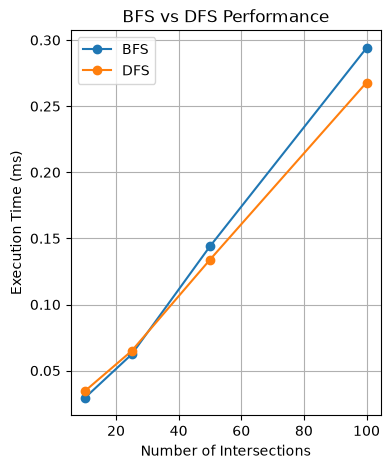

In [71]:
import matplotlib.pyplot as plt

traversal = benchmark_df[
    benchmark_df["Algorithm"].isin(["BFS", "DFS"])
]

pivot = traversal.pivot(
    index="Intersections",
    columns="Algorithm",
    values="Median Time (ms)"
)

pivot.plot(kind="line", marker="o", figsize=(4, 5))

plt.title("BFS vs DFS Performance")
plt.xlabel("Number of Intersections")
plt.ylabel("Execution Time (ms)")
plt.grid(True)
plt.legend()
plt.show()

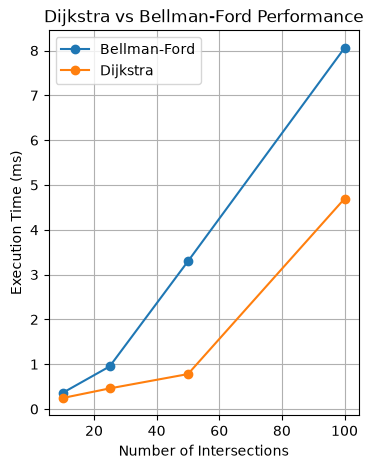

In [72]:
shortest_path = benchmark_df[
    benchmark_df["Algorithm"].isin(["Dijkstra", "Bellman-Ford"])
]

pivot = shortest_path.pivot(
    index="Intersections",
    columns="Algorithm",
    values="Median Time (ms)"
)

pivot.plot(kind="line", marker="o", figsize=(4, 5))

plt.title("Dijkstra vs Bellman-Ford Performance")
plt.xlabel("Number of Intersections")
plt.ylabel("Execution Time (ms)")
plt.grid(True)
plt.legend()
plt.show()

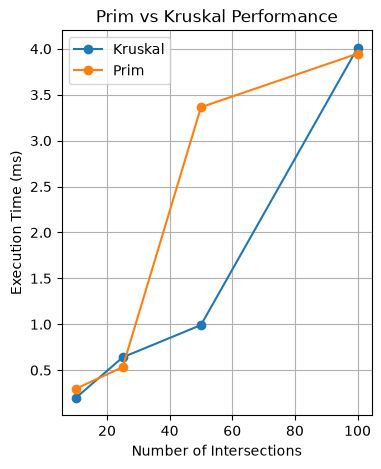

In [73]:
mst = benchmark_df[
    benchmark_df["Algorithm"].isin(["Prim", "Kruskal"])
]

pivot = mst.pivot(
    index="Intersections",
    columns="Algorithm",
    values="Median Time (ms)"
)

pivot.plot(kind="line", marker="o", figsize=(4, 5))

plt.title("Prim vs Kruskal Performance")
plt.xlabel("Number of Intersections")
plt.ylabel("Execution Time (ms)")
plt.grid(True)
plt.legend()
plt.show()

### Performance Analysis and Observations

The performance of six graph algorithms was evaluated using road networks containing 10, 25, 50, and 100 intersections.

**1. BFS vs DFS**

Both algorithms showed increasing execution time as the network size increased. Their performance was quite similar in the experiments. BFS was slightly faster for networks of 10 and 50 intersections, while DFS was slightly faster for 25 and 100 intersections.

**2. Dijkstra vs Bellman-Ford**

Dijkstra performed faster than Bellman-Ford across all four network sizes. At 100 intersections, Dijkstra took 2.6823 ms, whereas Bellman-Ford took 4.6307 ms. Both algorithms produced matching shortest-path costs in the experiments.

**3. Prim vs Kruskal**

Both algorithms successfully generated minimum spanning trees with the same minimum cost. Their execution times varied with network size. Kruskal performed faster at 10, 50, and 100 intersections, while Prim was faster at 25 intersections.

**Overall Observation**

The experiments show that execution time generally increases as the number of intersections and roads increases. Dijkstra was more efficient than Bellman-Ford for the tested networks, while BFS and DFS had similar traversal performance. Prim and Kruskal both produced equivalent minimum spanning tree costs.


## Create requirements.txt

In [74]:
%%writefile requirements.txt
streamlit
networkx
matplotlib
pandas
numpy
jupyter

Overwriting requirements.txt


In [75]:
with open("requirements.txt", "r") as file:
    print(file.read())

streamlit
networkx
matplotlib
pandas
numpy
jupyter

